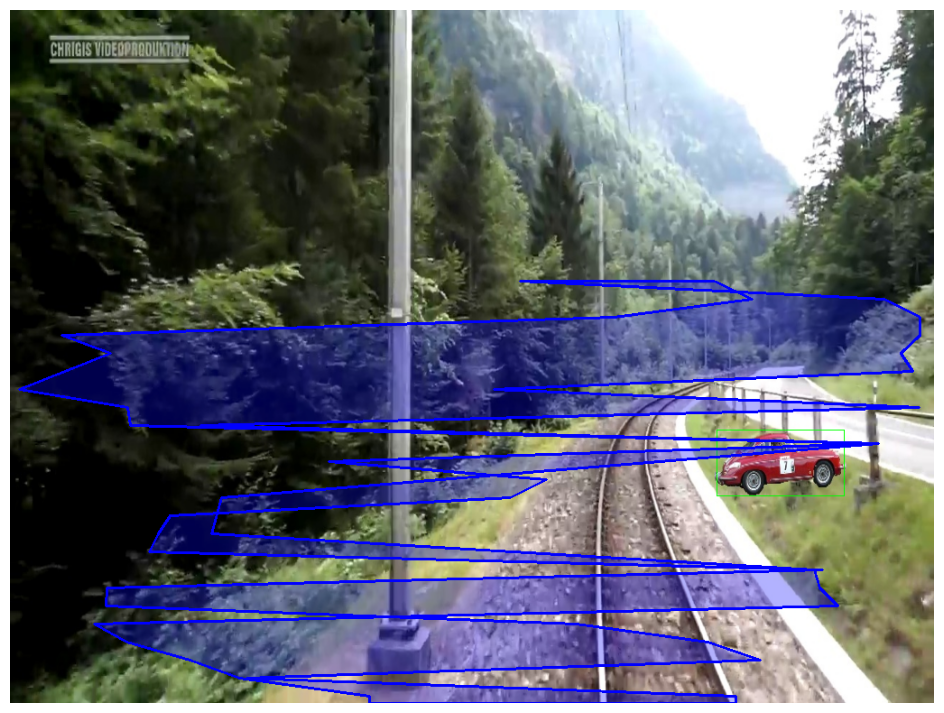

KeyboardInterrupt: 

In [2]:
import cv2
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
from ultralytics import YOLO

# 1. YOLOv8 modell betöltése
model = YOLO('yolov8n.pt')

# Mappa elérési útja
FOLDER_PATH = "testpics"

def find_track_polygon(image):
    """
    Stabil, horgonyzott dinamikus zóna, ami az alsó sínpontokra épül
    és követi a legmegbízhatóbb vonalakat.
    """
    height, width = image.shape[:2]
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Kép zajszűrése és élkeresés
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 50, 150)
    
    # Csak a kép alsó 60%-át nézzük
    roi_vertices = np.array([
        [(0, height), (width, height), (width, int(height*0.4)), (0, int(height*0.4))]
    ])
    mask = np.zeros_like(edges)
    cv2.fillPoly(mask, roi_vertices, 255)
    masked_edges = cv2.bitwise_and(edges, mask)
    
    # Vonalak keresése
    lines = cv2.HoughLinesP(masked_edges, 1, np.pi/180, threshold=40, minLineLength=40, maxLineGap=150)
    
    left_points = []
    right_points = []
    center_x = width / 2
    
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line.flatten()
            
            if y1 < y2:
                x1, y1, x2, y2 = x2, y2, x1, y1
                
            if x1 == x2: continue
            angle = np.arctan2(y1 - y2, abs(x2 - x1)) * 180 / np.pi
            if angle < 15 or angle > 85: 
                continue
                
            mid_x = (x1 + x2) / 2
            if mid_x < center_x:
                left_points.extend([(x1, y1), (x2, y2)])
            else:
                right_points.extend([(x1, y1), (x2, y2)])
                
    def get_smooth_path(points):
        if not points: return []
        bins = {}
        for x, y in points:
            bin_y = (y // 20) * 20
            if bin_y not in bins:
                bins[bin_y] = []
            bins[bin_y].append(x)
            
        path = []
        for bin_y in sorted(bins.keys(), reverse=True):
            med_x = int(np.median(bins[bin_y]))
            path.append((med_x, bin_y))
        return path
        
    left_path = get_smooth_path(left_points)
    right_path = get_smooth_path(right_points)
    
    if len(left_path) > 1 and len(right_path) > 1:
        min_y_left = left_path[-1][1]
        min_y_right = right_path[-1][1]
        stop_y = max(min_y_left, min_y_right) 
        
        final_left = [(x, y) for x, y in left_path if y >= stop_y]
        final_right = [(x, y) for x, y in right_path if y >= stop_y]
        
        if final_left and final_right:
            final_left.insert(0, (final_left[0][0], height))
            final_right.insert(0, (final_right[0][0], height))
            polygon_points = final_left + final_right[::-1]
            return np.array(polygon_points, np.int32)
            
    # BIZTONSÁGI TARTALÉK (FALLBACK)
    return np.array([
        [int(width * 0.3), height],
        [int(width * 0.7), height],
        [int(width * 0.55), int(height * 0.6)],
        [int(width * 0.45), int(height * 0.6)]
    ], np.int32)

def main():
    if not os.path.exists(FOLDER_PATH):
        print(f"Hiba: A '{FOLDER_PATH}' mappa nem létezik! Kérlek hozd létre és tegyél bele képeket.")
        return

    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    images = [f for f in os.listdir(FOLDER_PATH) if f.lower().endswith(valid_extensions)]
    
    if not images:
        print(f"A '{FOLDER_PATH}' mappa üres! Dobj bele pár képet.")
        return

    print("Képek feldolgozása indul...")

    # Maximum 10 véletlenszerű képet nézünk meg, hogy ne fusson a végtelenségig a Jupyterben
    for _ in range(10): 
        img_name = random.choice(images)
        img_path = os.path.join(FOLDER_PATH, img_name)
        frame = cv2.imread(img_path)
        
        if frame is None:
            continue

        frame = cv2.resize(frame, (1024, 768))
        
        # Sínpár keresése
        track_polygon = find_track_polygon(frame)
        
        # Objektumok felismerése YOLOv8-cal
        results = model(frame, verbose=False)
        
        obstacle_detected = False
        
        for result in results:
            boxes = result.boxes
            for box in boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                
                # Objektum "talpa" (középen lent)
                bottom_center = (int((x1 + x2) / 2), y2)
                
                # Benne van-e a pont a poligonban?
                is_inside = cv2.pointPolygonTest(track_polygon, bottom_center, False) >= 0
                
                if is_inside:
                    obstacle_detected = True
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 3) # Piros BGR-ben
                    cv2.circle(frame, bottom_center, 5, (0, 0, 255), -1)
                else:
                    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 1) # Zöld BGR-ben

        # Poligon rajzolása
        overlay = frame.copy()
        cv2.fillPoly(overlay, [track_polygon], (255, 0, 0)) # Kék BGR-ben
        cv2.addWeighted(overlay, 0.3, frame, 0.7, 0, frame)
        cv2.polylines(frame, [track_polygon], isClosed=True, color=(255, 0, 0), thickness=2)

        if obstacle_detected:
            cv2.rectangle(frame, (50, 50), (950, 150), (0, 0, 0), -1)
            cv2.putText(frame, "FIGYELEM! AKADALY A SINEN!", (70, 120), 
                        cv2.FONT_HERSHEY_SIMPLEX, 1.8, (0, 0, 255), 5)

        # OpenCV BGR formátumot használ, a Matplotlib pedig RGB-t, így konvertálni kell
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Kép megjelenítése Jupyter Notebookban
        clear_output(wait=True)
        plt.figure(figsize=(12, 9))
        plt.imshow(frame_rgb)
        plt.axis('off')
        plt.show()

        # 1,5 másodperc szünet a képek között
        time.sleep(1.5)
        
    print("Feldolgozás véget ért.")

if __name__ == "__main__":
    main()